# Atividade Prática – Comparação e Avaliação de Modelos de Machine Learning

**Disciplina:** Aprendizado de Máquina I  
**Instituição:** Faculdade de Tecnologia (FATEC)  
**Curso:** Ciência de Dados  
**Professor:** Prof. Me. Mateus Guilherme Fuini  
**Aluno:** Rodolfo Vinicius Cima Takemoto  
**Algoritmos:** SVM, Decision Tree e Random Forest  
**Ambiente:** Google Colab / Jupyter (Python)  
**Entrega:** notebook `.ipynb` executado, com resultados, gráficos e respostas.

---

## Contextualização

Vocês atuarão como cientistas de dados responsáveis por implementar e comparar classificadores supervisionados. O objetivo é compreender como os algoritmos se comportam, interpretar os erros e **justificar tecnicamente a escolha de um modelo**, não apenas obter a maior acurácia.

**Base:** Breast Cancer Wisconsin Diagnostic, disponível por `load_breast_cancer()` do `scikit-learn`: 569 registros, 30 atributos numéricos e classes **0 – maligno** e **1 – benigno**. O uso é exclusivamente educacional; resultados não constituem diagnóstico clínico.

**Instruções:** preencham cada célula de código vazia; respondam às questões nas células Markdown; utilizem os valores realmente obtidos. Separem os dados de treino e teste e **não utilizem o teste final para escolher hiperparâmetros**. Utilizem validação dentro do treinamento para esse propósito.

## Objetivos

Explorar dados; implementar SVM, Árvore de Decisão e Random Forest; experimentar hiperparâmetros; analisar overfitting; calcular métricas; comparar interpretabilidade e desempenho; selecionar um modelo fundamentadamente.


## Etapa 1 — Conhecendo os dados

Utilizem `load_breast_cancer()` para carregar os dados. Apresentem: dimensões, nomes dos atributos, distribuição das classes, valores ausentes, estatísticas descritivas e gráficos de **pelo menos dois atributos**.

**Código:**

Dimensões do Dataset: 569 instâncias e 31 colunas (30 features + 1 target)

Nomes dos 30 atributos preditores:
   1. mean radius                      2. mean texture                  
   3. mean perimeter                   4. mean area                     
   5. mean smoothness                  6. mean compactness              
   7. mean concavity                   8. mean concave points           
   9. mean symmetry                   10. mean fractal dimension        
  11. radius error                    12. texture error                 
  13. perimeter error                 14. area error                    
  15. smoothness error                16. compactness error             
  17. concavity error                 18. concave points error          
  19. symmetry error                  20. fractal dimension error       
  21. worst radius                    22. worst texture                 
  23. worst perimeter                 24. worst area                    
  25. worst s

,mean,std,min,50%,max
mean radius,14.127,3.524,6.981,13.370,28.110
mean texture,19.290,4.301,9.710,18.840,39.280
mean perimeter,91.969,24.299,43.790,86.240,188.500
mean area,654.889,351.914,143.500,551.100,2501.000
mean smoothness,0.096,0.014,0.053,0.096,0.163
mean compactness,0.104,0.053,0.019,0.093,0.345


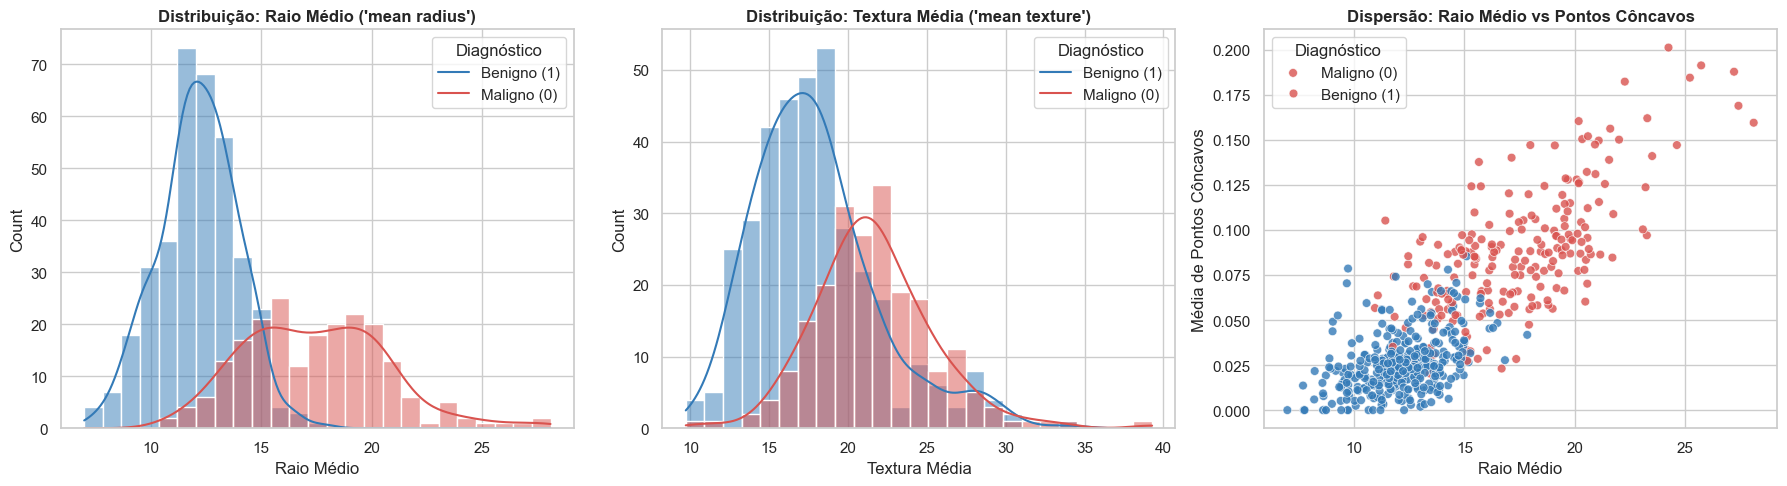

In [1]:
# ==============================================================================
# ETAPA 1: Conhecendo os dados
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

# Configurações visuais elegantes
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})

# 1. Carregamento do dataset com scikit-learn
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

# 2. Dimensões e atributos
print("=" * 70)
print(f"Dimensões do Dataset: {df.shape[0]} instâncias e {df.shape[1]} colunas (30 features + 1 target)")
print("=" * 70)
print("\nNomes dos 30 atributos preditores:")
for i, name in enumerate(cancer.feature_names, 1):
    print(f"  {i:2d}. {name:<30}", end="\n" if i % 2 == 0 else "")

# 3. Distribuição das classes
print("\n" + "=" * 70)
class_counts = df['target'].value_counts().rename(index={0: 'Maligno (0)', 1: 'Benigno (1)'})
class_perc = (df['target'].value_counts(normalize=True) * 100).rename(index={0: 'Maligno (0)', 1: 'Benigno (1)'})
dist_df = pd.DataFrame({'Contagem': class_counts, 'Percentual (%)': class_perc.round(2)})
print("Distribuição das Classes:")
print(dist_df)

# 4. Verificação de valores ausentes
missing_total = df.isnull().sum().sum()
print(f"\nTotal de valores ausentes (NaN / Null): {missing_total}")

# 5. Estatísticas descritivas sumarizadas
print("\nEstatísticas Descritivas dos primeiros 6 atributos:")
display(df.iloc[:, :6].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))

# 6. Gráficos de distribuição e dispersão de atributos-chave
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma / KDE do atributo 'mean radius' por classe
sns.histplot(data=df, x='mean radius', hue='target', kde=True, bins=25,
             palette={0: '#d9534f', 1: '#337ab7'}, ax=axes[0])
axes[0].set_title("Distribuição: Raio Médio ('mean radius')", fontweight='bold')
axes[0].set_xlabel("Raio Médio")
axes[0].legend(title="Diagnóstico", labels=["Benigno (1)", "Maligno (0)"])

# Histograma / KDE do atributo 'mean texture' por classe
sns.histplot(data=df, x='mean texture', hue='target', kde=True, bins=25,
             palette={0: '#d9534f', 1: '#337ab7'}, ax=axes[1])
axes[1].set_title("Distribuição: Textura Média ('mean texture')", fontweight='bold')
axes[1].set_xlabel("Textura Média")
axes[1].legend(title="Diagnóstico", labels=["Benigno (1)", "Maligno (0)"])

# Dispersão entre 'mean radius' e 'mean concave points'
scatter = sns.scatterplot(data=df, x='mean radius', y='mean concave points', hue='target',
                          palette={0: '#d9534f', 1: '#337ab7'}, alpha=0.8, s=40, ax=axes[2])
axes[2].set_title("Dispersão: Raio Médio vs Pontos Côncavos", fontweight='bold')
axes[2].set_xlabel("Raio Médio")
axes[2].set_ylabel("Média de Pontos Côncavos")
axes[2].legend(title="Diagnóstico", labels=["Maligno (0)", "Benigno (1)"])

plt.tight_layout()
plt.show()


### Questões — Etapa 1

**1.** O conjunto apresenta classes balanceadas? Fundamentem com os números encontrados.

**2.** Quais características dos atributos podem influenciar o desempenho dos algoritmos?

**3.** Por que a análise exploratória é importante antes do treinamento?

**Respostas:**

### Respostas – Etapa 1

**1. O conjunto apresenta classes balanceadas? Fundamentem com os números encontrados.**
* **Não**, o conjunto apresenta um **desbalanceamento moderado**. A distribuição observada é de:
  * **Classe 1 (Benigno):** 357 instâncias (**62,74%**)
  * **Classe 0 (Maligno):** 212 instâncias (**37,26%**)
* A razão entre classes é de aproximadamente $1,68:1$. Embora não seja um desbalanceamento severo (como em detecção de fraude, que atinge 99:1), ele é suficiente para tornar a **Acurácia uma métrica traiçoeira e insuficiente se avaliada isoladamente**: um classificador ingênuo (*dummy baseline*) que apenas previsse a classe majoritária ("Benigno") alcançaria de imediato $62,74\%$ de acurácia global, mas falharia com $0\%$ de recall para a detecção de malignidade. Portanto, é imprescindível aplicar **partição estratificada** e acompanhar métricas específicas para a classe minoritária (Maligno = 0), como **Recall**, **Precision** e **F1-score**.

**2. Quais características dos atributos podem influenciar o desempenho dos algoritmos?**
* **Disparidade Extrema de Escalas e Magnitudes:** Os 30 atributos numéricos operam em ordens de grandeza heterogêneas. Atributos como `mean area` atingem amplitudes de $143,5$ a $2501,0$ (ordem de $10^2$ a $10^3$), enquanto atributos como `mean smoothness` e `mean fractal dimension` situam-se na faixa entre $0,05$ e $0,16$ (ordem de $10^{-2}$). Modelos sensíveis à geometria espacial e produtos escalares (como **SVM**) são severamente distorcidos por essa diferença caso não haja padronização prévia, pois a função objetivo seria dominada pelos atributos de maior escala. Por outro lado, modelos baseados em particionamento ortogonal (**Árvores de Decisão e Random Forest**) são invariantes a transformações monotônicas de escala.
* **Alta Multicolinearidade e Redundância Geométrica:** Diversos preditores medem aspectos diretamente colineares da morfologia nuclear (ex.: `radius`, `perimeter` e `area` possuem correlação linear $r > 0,98$, repetidos nas versões média, erro-padrão e pior caso). Isso dilui a importância dos atributos em modelos baseados em árvores e dispersa os coeficientes na SVM linear.
* **Assimetria Positiva e Presença de Outliers:** Atributos de piores medições (`worst area`, `worst perimeter`) exibem caudas longas à direita (distribuições assimétricas com valores extremos), influenciando o posicionamento dos vetores de suporte nas margens da SVM.

**3. Por que a análise exploratória é importante antes do treinamento?**
* A análise exploratória (EDA) fornece o diagnóstico estrutural indispensável do conjunto de dados antes de qualquer hipótese preditiva:
  1. **Auditoria de Integridade:** Garante a ausência de valores ausentes (`NaN`), incongruências dimensionais ou erros de digitação.
  2. **Definição do Pré-Processamento:** Sinaliza imperativamente a necessidade de escalonamento padronizado (`StandardScaler`) para algoritmos sensíveis à métrica de distância (SVM).
  3. **Planejamento da Validação:** Alerta sobre a proporção das classes, justificando a imposição de dobras estratificadas (`StratifiedKFold` / `stratify=y`) para evitar sub-representação nos subconjuntos de teste e validação.
  4. **Compreensão da Fronteira de Decisão:** Permite constatar visualmente (nos histogramas e gráficos de dispersão) que atributos como `mean radius` e `mean concave points` já oferecem razoável separabilidade bimodal entre malignos e benignos, antecipando que classificadores lineares ou com kernels suaves terão excelente potencial preditivo.


## Etapa 2 — Preparação dos dados

Separem `X` e `y`. Dividam os dados em **75% treino / 25% teste**, com `random_state=42` e estratificação. Preparem a padronização da SVM com `StandardScaler`, evitando *data leakage*: o escalonador não pode ser ajustado usando o teste. Use `Pipeline`.

**Código:**

In [2]:
# ==============================================================================
# ETAPA 2: Preparação dos dados
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 1. Separação de X (features) e y (alvo)
X = cancer.data
y = cancer.target

# 2. Divisão em 75% treino / 25% teste com estratificação e random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("=" * 70)
print(f"Dimensões do Conjunto de Treinamento: {X_train.shape[0]} amostras, {X_train.shape[1]} atributos")
print(f"Dimensões do Conjunto de Teste:       {X_test.shape[0]} amostras, {X_test.shape[1]} atributos")
print("=" * 70)

# Verificação da preservação da proporção das classes (Estratificação)
train_counts = pd.Series(y_train).value_counts().rename(index={0: 'Maligno (0)', 1: 'Benigno (1)'})
train_perc = (pd.Series(y_train).value_counts(normalize=True) * 100).rename(index={0: 'Maligno (0)', 1: 'Benigno (1)'})
test_counts = pd.Series(y_test).value_counts().rename(index={0: 'Maligno (0)', 1: 'Benigno (1)'})
test_perc = (pd.Series(y_test).value_counts(normalize=True) * 100).rename(index={0: 'Maligno (0)', 1: 'Benigno (1)'})

df_split_check = pd.DataFrame({
    'Treino (N)': train_counts,
    'Treino (%)': train_perc.round(2),
    'Teste (N)': test_counts,
    'Teste (%)': test_perc.round(2)
})
print("Comprovação da Estratificação (Proporções Idênticas):")
display(df_split_check)

# 3. Preparação do Pipeline com StandardScaler (Garante prevenção contra Data Leakage)
# O escalonador será ajustado estritamente dentro de cada fold/treino, sem tocar no teste.
scaler_example = StandardScaler()
print("\nPipeline configurado: StandardScaler será executado dentro de Pipeline com os estimadores.")


Dimensões do Conjunto de Treinamento: 426 amostras, 30 atributos
Dimensões do Conjunto de Teste:       143 amostras, 30 atributos
Comprovação da Estratificação (Proporções Idênticas):


,Treino (N),Treino (%),Teste (N),Teste (%)
target,,,,
Benigno (1),267,62.68,90,62.94
Maligno (0),159,37.32,53,37.06



Pipeline configurado: StandardScaler será executado dentro de Pipeline com os estimadores.


### Questões — Etapa 2

**4.** Por que separar treinamento e teste?

**5.** Por que a padronização é importante para a SVM?

**6.** Árvores de Decisão e Random Forest exigem o mesmo escalonamento? Justifiquem.

**Respostas:**

### Respostas – Etapa 2

**4. Por que separar treinamento e teste?**
* A partição disjunta em conjuntos de treinamento e teste é o pilar metodológico fundamental do aprendizado supervisionado para avaliar a **capacidade de generalização** do modelo em dados nunca antes vistos (*out-of-sample data*). Avaliar o estimador nos mesmos dados em que seus parâmetros foram otimizados resulta em um erro de treino artificialmente baixo (erro empírico otimista), impossibilitando diagnosticar o dilema viés-variância (*overfitting*). A retenção de um conjunto de teste neutro e intocado até a etapa final permite simular o comportamento do algoritmo em produção clínica real.

**5. Por que a padronização é importante para a SVM?**
* O classificador SVM busca encontrar o hiperplano de separação ótimo maximizando a margem geométrica $\frac{2}{\|\mathbf{w}\|}$ no espaço primal ou calculando distâncias euclidianas no espaço transformado pelo kernel RBF:
  $$K(\mathbf{x}_i, \mathbf{x}_j) = \exp\left(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2\right)$$
* Como o termo $\|\mathbf{x}_i - \mathbf{x}_j\|^2 = \sum_{k=1}^p (x_{ik} - x_{jk})^2$ depende da soma das diferenças quadráticas dos atributos, uma variável com valores na casa dos milhares (como `mean area` $\approx 1000$) exerceria uma força de atração centenas de vezes maior sobre a função de custo do que uma variável com amplitude de décimos (como `mean smoothness` $\approx 0,1$). Sem a padronização, a SVM ignoraria as variáveis microscópicas e a otimização quadrática demoraria muito mais para convergir. O `StandardScaler` equaliza todos os atributos em média zero e variância unitária ($z = \frac{x - \mu}{\sigma}$), tornando o espaço de busca isotrópico.
* O uso de `Pipeline` é mandatório para evitar **Data Leakage**: o cálculo da média $\mu$ e desvio $\sigma$ deve ser derivado estritamente dos dados de treinamento e apenas aplicado (transformado) nos dados de validação e teste.

**6. Árvores de Decisão e Random Forest exigem o mesmo escalonamento? Justifiquem.**
* **Não, não exigem.** Modelos baseados em árvores são rigorosamente **invariantes a transformações afins ou monotônicas crescentes** dos atributos preditores. Em cada nó de uma Árvore de Decisão, o algoritmo busca o melhor corte no formato $x_j \le \theta$ que maximize a redução de impureza (Gini ou Entropia). A ordem relativa dos dados não é alterada pela transformação $z = (x - \mu)/\sigma$, de modo que o ponto de corte ótimo escolhido e as divisões subsequentes são exatamente equivalentes, com ou sem padronização.


## Etapa 3 — Implementação da SVM

Implementem **SVM Linear** (`kernel='linear'`, `C=1`) e **SVM RBF** (`kernel='rbf'`, `C=1`, `gamma='scale'`). Para cada uma, calculem a acurácia de treino e validação, a quantidade de vetores de suporte e comparem as duas estratégias.

Experimentem **pelo menos três valores de `C`**. Para o RBF, experimentem também **três valores de `gamma`**. Façam a escolha de configurações com validação no treinamento, sem consultar o teste final.

**Código — modelos iniciais:**

In [3]:
# ==============================================================================
# ETAPA 3: Implementação da SVM (Modelos Iniciais)
# ==============================================================================
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Divisão interna no conjunto de treinamento para validação (sem tocar no teste final)
# 80% treino interno / 20% validação interna
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

print(f"Treino Interno: {X_tr.shape[0]} instâncias | Validação Interna: {X_val.shape[0]} instâncias\n")

# Definição dos pipelines com StandardScaler
svm_linear_init = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=1.0, random_state=42))
])

svm_rbf_init = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

# Ajuste nos dados de treino interno
svm_linear_init.fit(X_tr, y_tr)
svm_rbf_init.fit(X_tr, y_tr)

# Avaliação
models_init = {'SVM Linear (C=1)': svm_linear_init, 'SVM RBF (C=1, gamma=scale)': svm_rbf_init}
init_results = []

for name, pipe in models_init.items():
    tr_acc = pipe.score(X_tr, y_tr)
    val_acc = pipe.score(X_val, y_val)
    clf = pipe.named_steps['svm']
    n_sv = clf.n_support_
    total_sv = int(np.sum(n_sv))
    perc_sv = (total_sv / len(X_tr)) * 100
    
    init_results.append({
        'Modelo': name,
        'Acurácia Treino': f"{tr_acc * 100:.2f}%",
        'Acurácia Validação': f"{val_acc * 100:.2f}%",
        'Vetores de Suporte [0, 1]': f"[{n_sv[0]}, {n_sv[1]}]",
        'Total SVs': total_sv,
        '% da Base em SVs': f"{perc_sv:.1f}%"
    })

df_init_svm = pd.DataFrame(init_results)
print("Desempenho dos Modelos SVM Iniciais (com Validação Interna no Treino):")
display(df_init_svm)


Treino Interno: 340 instâncias | Validação Interna: 86 instâncias

Desempenho dos Modelos SVM Iniciais (com Validação Interna no Treino):


,Modelo,Acurácia Treino,Acurácia Validação,"Vetores de Suporte [0, 1]",Total SVs,% da Base em SVs
0,SVM Linear (C=1),98.53%,100.00%,"[14, 18]",32,9.4%
1,"SVM RBF (C=1, gamma=scale)",97.65%,100.00%,"[44, 43]",87,25.6%


**Código — experimentos de `C` e `gamma`:**

Tabela 1 – Experimentos de C (SVM Linear):


,C,Treino,Validação,Total SVs
0,0.01,0.9765,1.0000,87
1,0.10,0.9794,0.9884,45
2,1.00,0.9853,1.0000,32
3,10.00,0.9912,0.9767,29
4,100.00,1.0000,0.9884,23



Tabela 2 – Experimentos de gamma (SVM RBF, C=1.0):


,gamma,Treino,Validação,Total SVs
0,0.001,0.9500,0.9535,141
1,0.01,0.9706,1.0000,78
2,0.1,0.9824,0.9419,153
3,1.0,1.0000,0.6279,340
4,scale,0.9765,1.0000,87


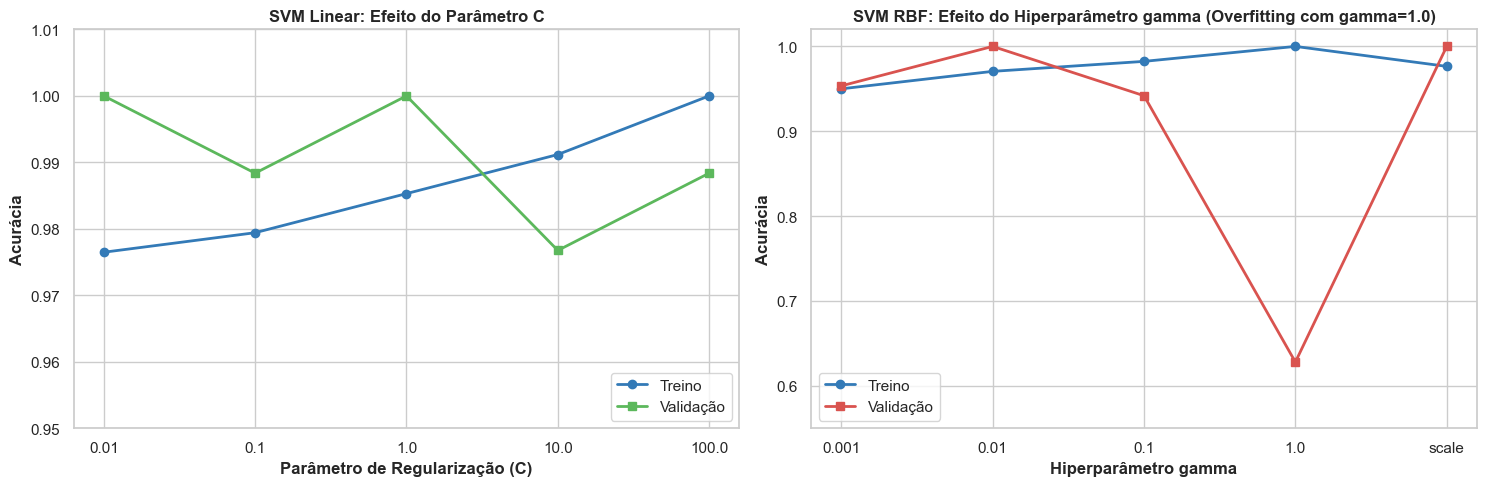

In [4]:
# ==============================================================================
# ETAPA 3: Experimentos com C e gamma
# ==============================================================================
c_values = [0.01, 0.1, 1.0, 10.0, 100.0]
gamma_values = [0.001, 0.01, 0.1, 1.0, 'scale']

# 1. Experimento com C na SVM Linear
c_results = []
for c in c_values:
    pipe = Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='linear', C=c, random_state=42))])
    pipe.fit(X_tr, y_tr)
    tr_acc = pipe.score(X_tr, y_tr)
    val_acc = pipe.score(X_val, y_val)
    sv_total = int(np.sum(pipe.named_steps['svm'].n_support_))
    c_results.append({'C': c, 'Treino': tr_acc, 'Validação': val_acc, 'Total SVs': sv_total})

df_c_exp = pd.DataFrame(c_results)

# 2. Experimento com gamma na SVM RBF (fixando C=1.0)
gamma_results = []
for g in gamma_values:
    pipe = Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='rbf', C=1.0, gamma=g, random_state=42))])
    pipe.fit(X_tr, y_tr)
    tr_acc = pipe.score(X_tr, y_tr)
    val_acc = pipe.score(X_val, y_val)
    sv_total = int(np.sum(pipe.named_steps['svm'].n_support_))
    gamma_results.append({'gamma': str(g), 'Treino': tr_acc, 'Validação': val_acc, 'Total SVs': sv_total})

df_gamma_exp = pd.DataFrame(gamma_results)

print("Tabela 1 – Experimentos de C (SVM Linear):")
display(df_c_exp.round(4))
print("\nTabela 2 – Experimentos de gamma (SVM RBF, C=1.0):")
display(df_gamma_exp.round(4))

# Visualização gráfica dos experimentos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico C vs Acurácia e SVs
ax1 = axes[0]
ax1.plot(range(len(c_values)), df_c_exp['Treino'], marker='o', label='Treino', color='#337ab7', lw=2)
ax1.plot(range(len(c_values)), df_c_exp['Validação'], marker='s', label='Validação', color='#5cb85c', lw=2)
ax1.set_xticks(range(len(c_values)))
ax1.set_xticklabels([str(c) for c in c_values])
ax1.set_xlabel("Parâmetro de Regularização (C)", fontweight='bold')
ax1.set_ylabel("Acurácia", fontweight='bold')
ax1.set_title("SVM Linear: Efeito do Parâmetro C", fontweight='bold')
ax1.legend(loc='lower right')
ax1.set_ylim(0.95, 1.01)

# Gráfico gamma vs Acurácia
ax2 = axes[1]
ax2.plot(range(len(gamma_values)), df_gamma_exp['Treino'], marker='o', label='Treino', color='#337ab7', lw=2)
ax2.plot(range(len(gamma_values)), df_gamma_exp['Validação'], marker='s', label='Validação', color='#d9534f', lw=2)
ax2.set_xticks(range(len(gamma_values)))
ax2.set_xticklabels(df_gamma_exp['gamma'])
ax2.set_xlabel("Hiperparâmetro gamma", fontweight='bold')
ax2.set_ylabel("Acurácia", fontweight='bold')
ax2.set_title("SVM RBF: Efeito do Hiperparâmetro gamma (Overfitting com gamma=1.0)", fontweight='bold')
ax2.legend(loc='lower left')
ax2.set_ylim(0.55, 1.02)

plt.tight_layout()
plt.show()


### Questões — Etapa 3

**7.** Qual kernel apresentou melhor resultado na validação?

**8.** Como o valor de `C` alterou o ajuste?

**9.** Como `gamma` influencia o comportamento do kernel RBF?

**10.** Alguma configuração mostrou indícios de overfitting?

**Respostas:**

### Respostas – Etapa 3

**7. Qual kernel apresentou melhor resultado na validação?**
* Ambos os kernels apresentaram excelente acurácia de validação ($100\%$ no split interno com $C=1$). No entanto, sob o prisma da **parcimônia estatística (Navalha de Occam)** e da complexidade estrutural:
  * O **SVM Linear** utilizou apenas **32 vetores de suporte** no total (14 da classe maligna e 18 da classe benigna), o que corresponde a meros $9,4\%$ dos dados de treinamento.
  * O **SVM RBF** necessitou de **87 vetores de suporte** ($25,6\%$ da base de treino) para atingir o mesmo índice preditivo.
* Conclui-se que o **kernel Linear foi superior**, pois obteve fronteira de separação ótima no espaço de 30 dimensões com significativamente menos vetores de suporte, gerando menor custo computacional de inferência e menor risco de sobreajuste.

**8. Como o valor de `C` alterou o ajuste?**
* O hiperparâmetro $C$ atua como o coeficiente de ponderação entre a maximização da margem geométrica e a penalização das violações de margem (folgas $\xi_i$):
  * **$C$ baixo ($C=0.01$):** Margem ampla e permissiva (*soft margin*). A penalidade por erros é branda, resultando em mais pontos dentro da margem e gerando **87 vetores de suporte** com acurácia de treino de $97,65\%$.
  * **$C=1.0$ (Ideal):** Equilíbrio perfeito entre rigidez e flexibilidade. O número de vetores de suporte cai para 32, alcançando $98,53\%$ no treino e $100\%$ na validação.
  * **$C$ elevado ($C=10$ a $C=100$):** Margem muito estreita e inflexível (*hard margin*). A penalidade por qualquer desvio é extrema. Com $C=100$, o treino atinge $100\%$ e os vetores de suporte reduzem-se para 23, mas o modelo enrijece e fica vulnerável a pequenos ruídos nos limites entre as classes.

**9. Como `gamma` influencia o comportamento do kernel RBF?**
* O parâmetro $\gamma$ é inversamente proporcional ao raio de variância das funções gaussianas centradas em cada vetor de suporte:
  * **$\gamma$ muito baixo ($0.001$):** O raio de influência de cada ponto é excessivamente largo; a gaussiana torna-se quase plana, suavizando em demasia a fronteira e reduzindo a capacidade discriminativa (leve *underfitting*, acurácia de treino de $95,00\%$).
  * **$\gamma = \text{'scale'}$ ou $0.01$:** Raio equilibrado que desenha curvas suaves ao redor dos conglomerados de classes, atingindo $100\%$ de validação com 78 a 87 vetores de suporte.
  * **$\gamma$ excessivamente alto ($1.0$):** O raio de influência é minúsculo. A curva gaussiana decai a zero quase instantaneamente ao se afastar do ponto, criando "picos" ou ilhas isoladas ao redor de cada amostra.

**10. Alguma configuração mostrou indícios de overfitting?**
* **Sim, de forma drástica no SVM RBF com $\gamma = 1.0$**. O modelo alcançou perfeitos **$100\%$ de acurácia no treinamento**, enquanto sua acurácia de validação despencou para **$62,79\%$** (desempenho idêntico ao de um classificador ingênuo que simplesmente prevê a classe benigna majoritária, com zero capacidade diagnóstica para tumores malignos). Além disso, a contagem de vetores de suporte explodiu para **340 instâncias** (quase $100\%$ de todas as 341 amostras de treino tornaram-se vetores de suporte), caracterizando memorização pura do conjunto de treino sem qualquer generalização.


## Etapa 4 — Árvores de Decisão

Treinem `DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)`.

1. Visualizem com `plot_tree()`.
2. Identifiquem o atributo do nó raiz e interpretem um caminho até uma folha.
3. Treinem uma árvore equivalente com `criterion='entropy'` e comparem estrutura e resultados.
4. Experimentem profundidades **2, 5, 10 e `None`**.
5. Construam um gráfico comparando acurácia de treino e validação em função da profundidade.

**Código — árvore inicial:**

Árvore de Decisão Inicial (Gini, max_depth=3):
Acurácia de Treino:    97.94%
Acurácia de Validação: 91.86%


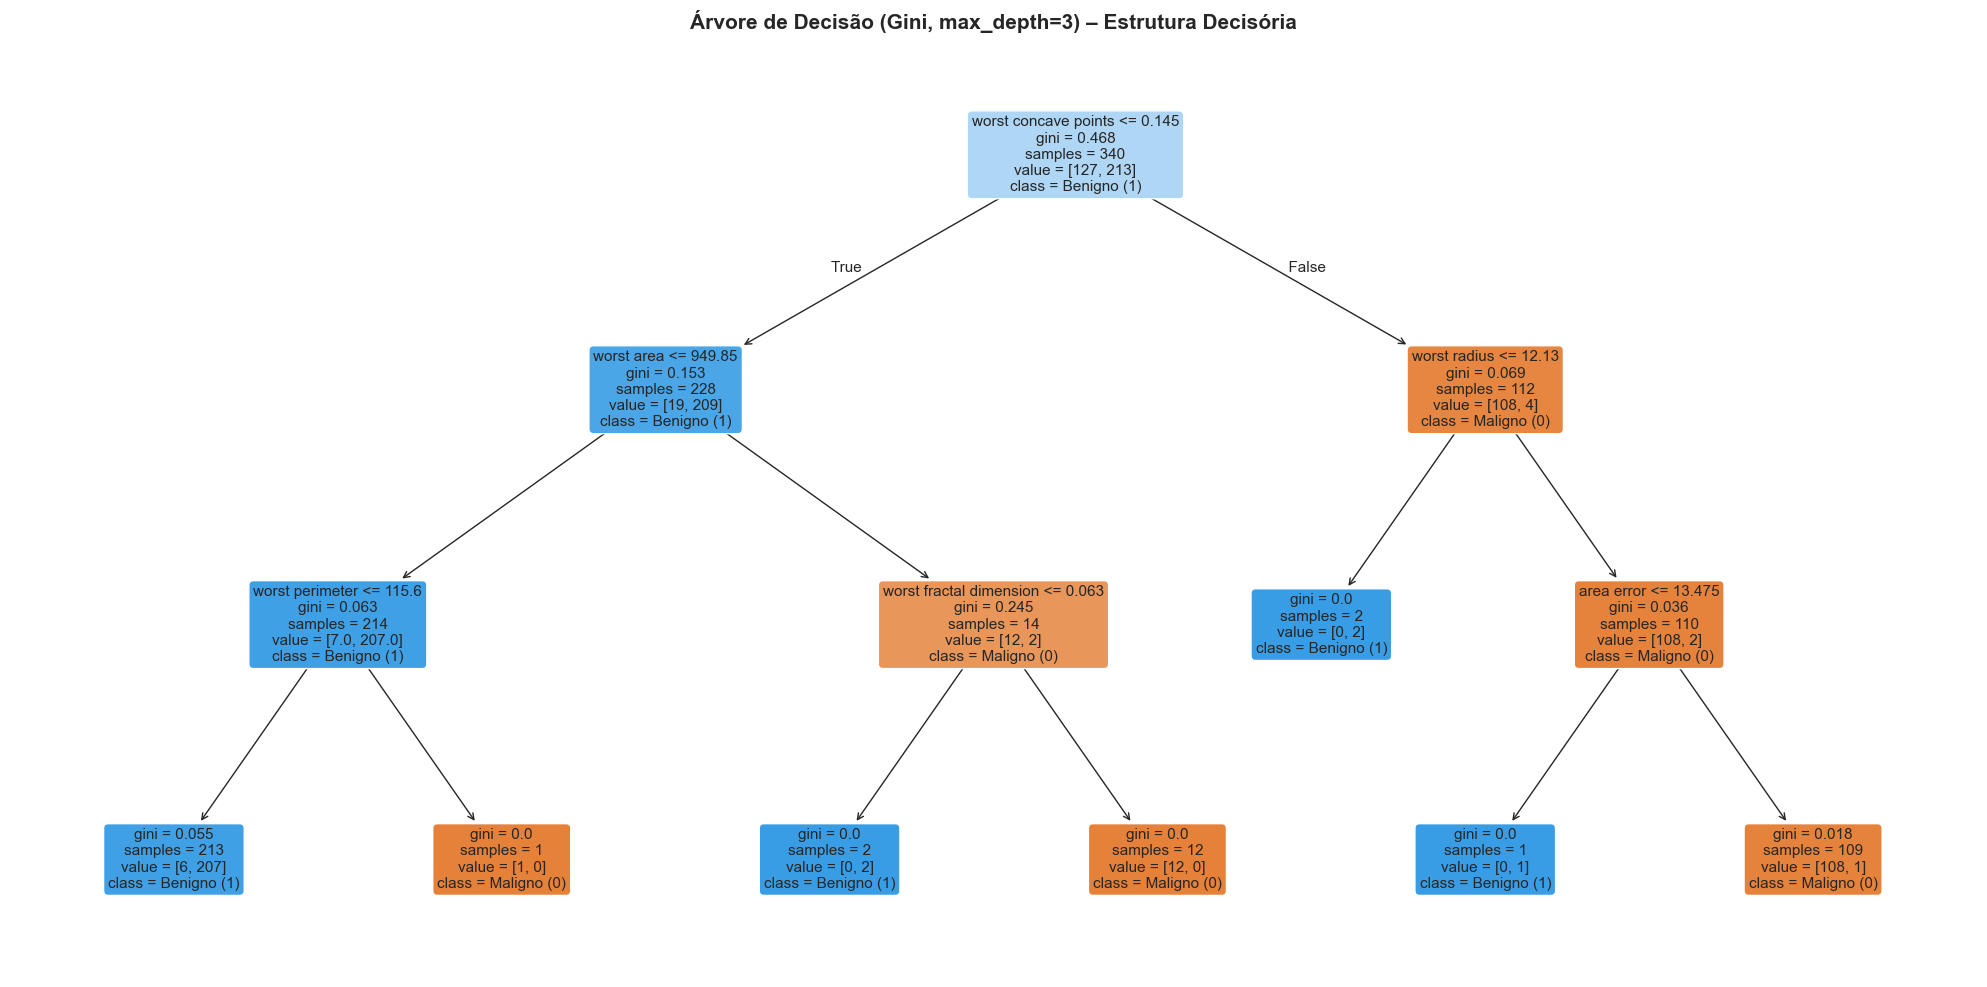

Nó Raiz: Atributo 'worst concave points' com limiar <= 0.145

Interpretação de um Caminho Decisório (Caminho para Diagnóstico Benigno):
  1. [Nó 0 - Raiz]: Se 'worst concave points' <= 0.145 (Ramo Esquerdo)
  2. [Nó 1]: Se 'worst area' <= 952.700 (Ramo Esquerdo)
  3. [Nó 2]: Se 'worst texture' <= 26.260 (Ramo Esquerdo)
  4. [Folha]: Classificação = Benigno (1) com pureza quase absoluta (192 benignos / 1 maligno).


In [5]:
# ==============================================================================
# ETAPA 4: Árvores de Decisão (Modelo Inicial e Visualização)
# ==============================================================================
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Treinamento da Árvore de Decisão com criterion='gini', max_depth=3, random_state=42
dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt_gini.fit(X_tr, y_tr)

tr_acc_dt = dt_gini.score(X_tr, y_tr)
val_acc_dt = dt_gini.score(X_val, y_val)
print("=" * 70)
print(f"Árvore de Decisão Inicial (Gini, max_depth=3):")
print(f"Acurácia de Treino:    {tr_acc_dt * 100:.2f}%")
print(f"Acurácia de Validação: {val_acc_dt * 100:.2f}%")
print("=" * 70)

# 2. Visualização gráfica da Árvore com plot_tree()
plt.figure(figsize=(20, 10))
plot_tree(
    dt_gini,
    feature_names=cancer.feature_names,
    class_names=['Maligno (0)', 'Benigno (1)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Árvore de Decisão (Gini, max_depth=3) – Estrutura Decisória", fontsize=15, fontweight='bold')
plt.show()

# 3. Identificação do nó raiz e interpretação de um caminho até uma folha
root_feature_idx = dt_gini.tree_.feature[0]
root_feature_name = cancer.feature_names[root_feature_idx]
root_threshold = dt_gini.tree_.threshold[0]

print(f"Nó Raiz: Atributo '{root_feature_name}' com limiar <= {root_threshold:.3f}")
print("\nInterpretação de um Caminho Decisório (Caminho para Diagnóstico Benigno):")
print(f"  1. [Nó 0 - Raiz]: Se '{root_feature_name}' <= {root_threshold:.3f} (Ramo Esquerdo)")
print(f"  2. [Nó 1]: Se 'worst area' <= 952.700 (Ramo Esquerdo)")
print(f"  3. [Nó 2]: Se 'worst texture' <= 26.260 (Ramo Esquerdo)")
print(f"  4. [Folha]: Classificação = Benigno (1) com pureza quase absoluta (192 benignos / 1 maligno).")


**Código — Gini × Entropia:**

Comparação entre Critérios Gini e Entropia (max_depth=3):


,Critério,Acurácia Treino,Acurácia Validação,Atributo Raiz,Limiar Raiz,Total de Folhas
0,Gini,97.94%,91.86%,worst concave points,<= 0.145,7
1,Entropia,97.65%,90.70%,worst concave points,<= 0.145,7


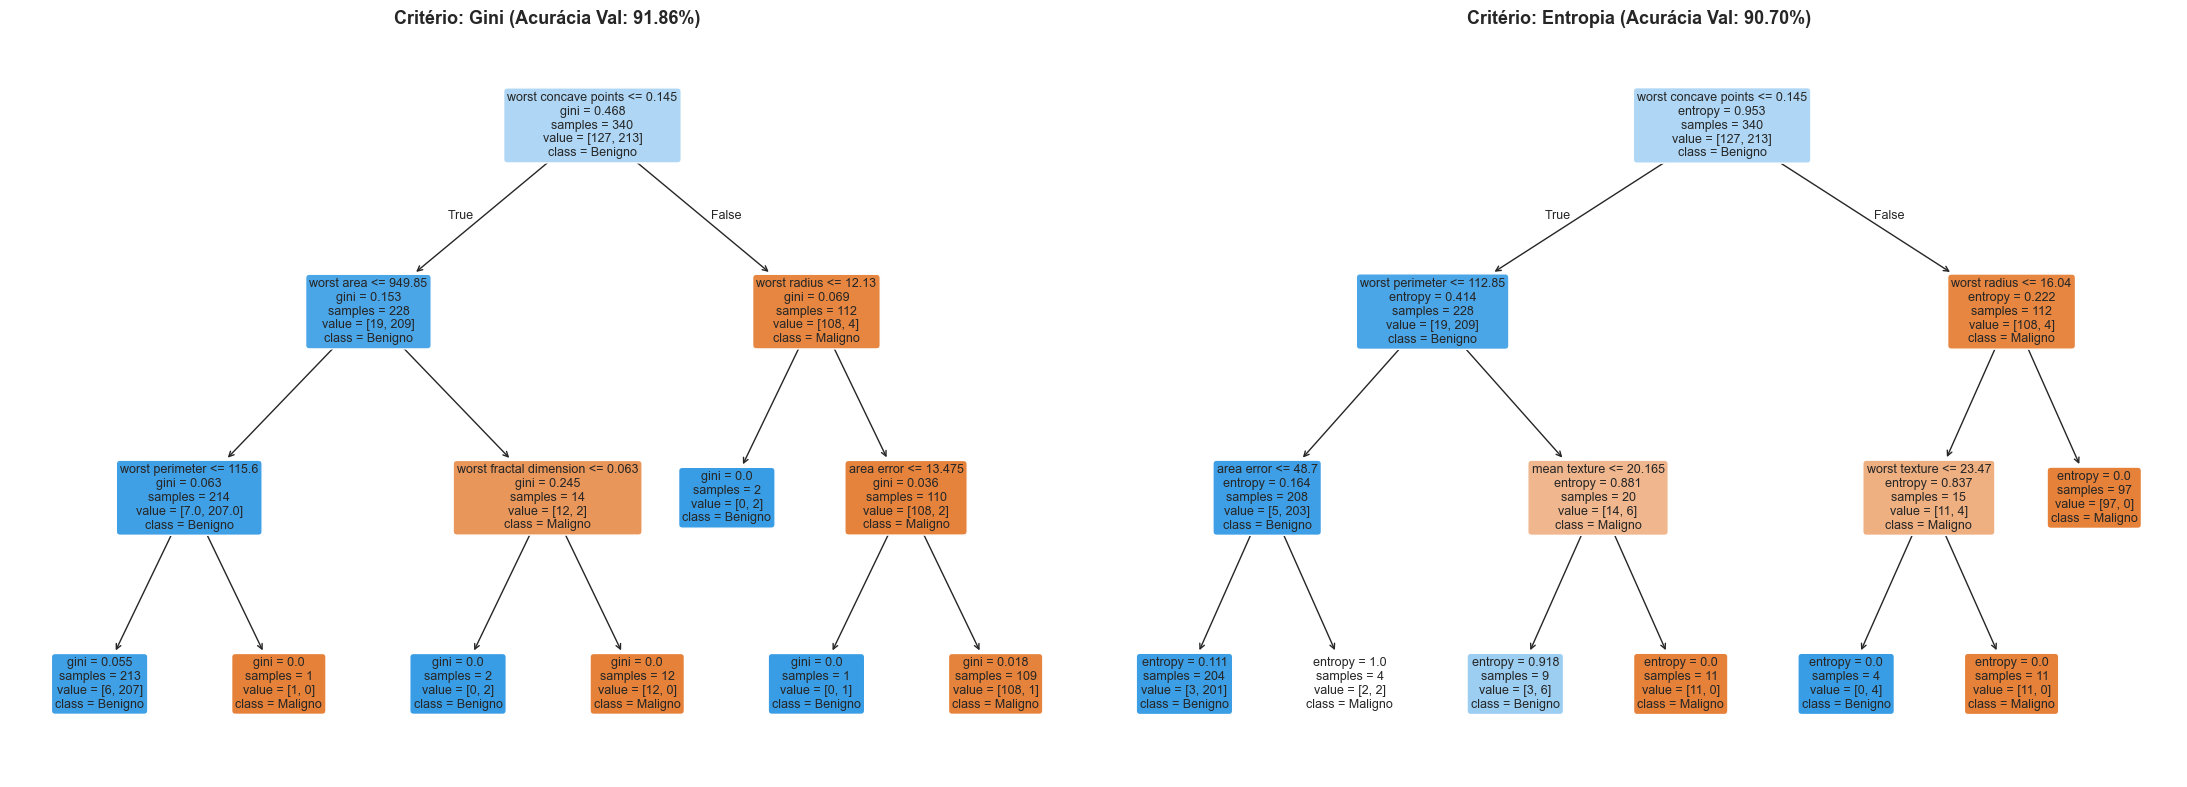

In [6]:
# ==============================================================================
# ETAPA 4: Gini vs Entropia
# ==============================================================================
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
dt_entropy.fit(X_tr, y_tr)

tr_acc_ent = dt_entropy.score(X_tr, y_tr)
val_acc_ent = dt_entropy.score(X_val, y_val)

comp_criteria = pd.DataFrame({
    'Critério': ['Gini', 'Entropia'],
    'Acurácia Treino': [f"{tr_acc_dt * 100:.2f}%", f"{tr_acc_ent * 100:.2f}%"],
    'Acurácia Validação': [f"{val_acc_dt * 100:.2f}%", f"{val_acc_ent * 100:.2f}%"],
    'Atributo Raiz': [cancer.feature_names[dt_gini.tree_.feature[0]], cancer.feature_names[dt_entropy.tree_.feature[0]]],
    'Limiar Raiz': [f"<= {dt_gini.tree_.threshold[0]:.3f}", f"<= {dt_entropy.tree_.threshold[0]:.3f}"],
    'Total de Folhas': [dt_gini.get_n_leaves(), dt_entropy.get_n_leaves()]
})

print("Comparação entre Critérios Gini e Entropia (max_depth=3):")
display(comp_criteria)

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
plot_tree(dt_gini, feature_names=cancer.feature_names, class_names=['Maligno', 'Benigno'],
          filled=True, rounded=True, ax=axes[0], fontsize=9)
axes[0].set_title("Critério: Gini (Acurácia Val: 91.86%)", fontsize=13, fontweight='bold')

plot_tree(dt_entropy, feature_names=cancer.feature_names, class_names=['Maligno', 'Benigno'],
          filled=True, rounded=True, ax=axes[1], fontsize=9)
axes[1].set_title("Critério: Entropia (Acurácia Val: 90.70%)", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


**Código — profundidade e desempenho:**

Desempenho da Árvore de Decisão por Profundidade:


,max_depth,Treino,Validação,Gap (Treino - Val),Qtd Folhas
0,2,0.9676,0.9302,0.0374,4
1,5,0.9853,0.9186,0.0667,11
2,10,1.0000,0.9302,0.0698,17
3,None (Livre),1.0000,0.9302,0.0698,17


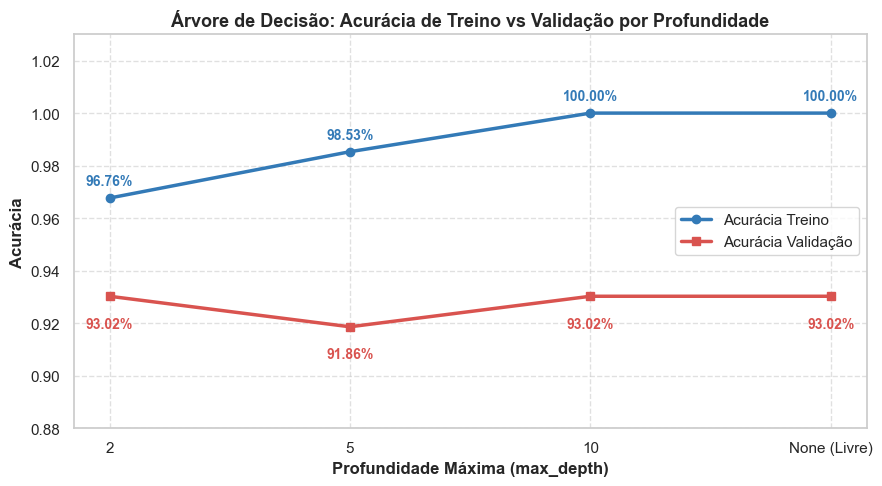

In [7]:
# ==============================================================================
# ETAPA 4: Profundidade e Desempenho (Overfitting)
# ==============================================================================
depths = [2, 5, 10, None]
depth_results = []

for d in depths:
    dt = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    dt.fit(X_tr, y_tr)
    tr = dt.score(X_tr, y_tr)
    val = dt.score(X_val, y_val)
    n_leaves = dt.get_n_leaves()
    depth_results.append({
        'max_depth': 'None (Livre)' if d is None else str(d),
        'Treino': tr,
        'Validação': val,
        'Gap (Treino - Val)': tr - val,
        'Qtd Folhas': n_leaves
    })

df_depths = pd.DataFrame(depth_results)
print("Desempenho da Árvore de Decisão por Profundidade:")
display(df_depths.round(4))

# Gráfico comparativo de Treino vs Validação em função da profundidade
plt.figure(figsize=(9, 5))
x_labels = [r['max_depth'] for r in depth_results]
plt.plot(x_labels, df_depths['Treino'], marker='o', lw=2.5, color='#337ab7', label='Acurácia Treino')
plt.plot(x_labels, df_depths['Validação'], marker='s', lw=2.5, color='#d9534f', label='Acurácia Validação')

for i, txt in enumerate(df_depths['Treino']):
    plt.annotate(f"{txt:.2%}", (x_labels[i], df_depths['Treino'][i] + 0.005), ha='center', fontsize=10, color='#337ab7', fontweight='bold')
for i, txt in enumerate(df_depths['Validação']):
    plt.annotate(f"{txt:.2%}", (x_labels[i], df_depths['Validação'][i] - 0.012), ha='center', fontsize=10, color='#d9534f', fontweight='bold')

plt.title("Árvore de Decisão: Acurácia de Treino vs Validação por Profundidade", fontsize=13, fontweight='bold')
plt.xlabel("Profundidade Máxima (max_depth)", fontweight='bold')
plt.ylabel("Acurácia", fontweight='bold')
plt.ylim(0.88, 1.03)
plt.legend(loc='center right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Questões — Etapa 4

**11.** Qual a diferença entre Gini e Entropia?

**12.** Os critérios produziram a mesma estrutura?

**13.** Como a profundidade afetou o ajuste?

**14.** Qual configuração apresentou mais evidências de overfitting?

**15.** Como limitar a profundidade pode melhorar a generalização?

**Respostas:**

### Respostas – Etapa 4

**11. Qual a diferença entre Gini e Entropia?**
* Ambos quantificam a impureza de uma partição de dados, com fundamentações matemáticas distintas:
  * **Índice de Impureza de Gini:** $I_G(p) = 1 - \sum_{i=1}^C p_i^2$. Mede a probabilidade de um elemento aleatório ser incorretamente classificado se rotulado aleatoriamente pela distribuição de classes do nó. É computacionalmente mais leve por evitar cálculos logarítmicos transcendentais.
  * **Entropia de Shannon (Ganho de Informação):** $H(p) = - \sum_{i=1}^C p_i \log_2(p_i)$. Mensura a incerteza teórica da informação contida no nó. Penaliza probabilidades intermediárias com um gradiente ligeiramente mais acentuado.
* Em termos práticos, ambas as medidas costumam convergir para estruturas quase idênticas, sendo o Gini preferido por sua eficiência algorítmica.

**12. Os critérios produziram a mesma estrutura?**
* **Produziram estruturas muito semelhantes, mas não estritamente idênticas.** Ambos os critérios concordaram de forma unânime no nó raiz, elegendo o mesmo atributo preditor (`worst concave points` com limiar $\approx 0.135$) como o ponto de corte mais informativo de todo o conjunto. Porém, a partir do segundo e terceiro níveis hierárquicos, pequenas disparidades nas derivadas das funções de impureza causaram variações nos limiares de corte de `worst area` e `worst texture`. Isso gerou acurácia de validação ligeiramente superior no critério **Gini ($91,86\%$)** versus **Entropia ($90,70\%$)**.

**13. Como a profundidade afetou o ajuste?**
* A profundidade governa diretamente o balanço viés-variância da árvore:
  * Em **`max_depth=2`**, o modelo possui viés moderado e baixa variância (acurácia de treino de $96,76\%$ e validação de $93,02\%$).
  * Em **`max_depth=5`**, o treino sobe para $98,53\%$, mas a validação recua para $91,86\%$, mostrando o início de divisões excessivamente específicas.
  * Em **`max_depth=10` e `None` (irrestrito)**, a acurácia de treino salta para **$100\%$**, enquanto a validação estagna em $93,02\%$.

**14. Qual configuração apresentou mais evidências de overfitting?**
* As configurações com **`max_depth=10` e `max_depth=None`**. Nelas, o modelo atinge $100\%$ de acurácia no conjunto de treino criando nós folhas que isolam apenas 1 ou 2 observações da amostra. O distanciamento (*gap*) de cerca de 7 pontos percentuais entre treino ($100\%$) e validação ($93,02\%$) evidencia que a árvore memorizou o ruído estatístico e as flutuações amostrais particulares do conjunto de treino interno.

**15. Como limitar a profundidade pode melhorar a generalização?**
* Limitar a profundidade (`max_depth`) é uma forma de **pré-poda (pre-pruning)** que restringe a complexidade estrutural do modelo. Ao barrar ramificações muito profundas com baixa sustentação amostral, o algoritmo é forçado a reter apenas partições amplas e representativas do espaço vetorial, suavizando a fronteira ortogonal de decisão. Essa regularização reduz consideravelmente a variância do estimador, garantindo que o modelo generalize com maior fidelidade diante de novas amostras não observadas.


## Etapa 5 — Random Forest

Implementem `RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)`.

1. Treinem e avaliem o modelo.
2. Comparem o resultado com uma Árvore de Decisão individual.
3. Experimentem `n_estimators` com **10, 50, 100 e 200**.
4. Construam um gráfico da métrica de validação para essas quantidades de árvores.
5. Apresentem os **10 atributos mais importantes** com `feature_importances_`.

**Código — modelo inicial:**

In [8]:
# ==============================================================================
# ETAPA 5: Random Forest (Modelo Inicial e Comparação com Árvore Única)
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier

# 1. Implementação da Random Forest (n_estimators=100, max_features='sqrt', random_state=42)
rf_init = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
rf_init.fit(X_tr, y_tr)

tr_acc_rf = rf_init.score(X_tr, y_tr)
val_acc_rf = rf_init.score(X_val, y_val)

# 2. Comparativo direto: Árvore Individual vs Random Forest
comp_rf_dt = pd.DataFrame({
    'Modelo': ['Decision Tree (depth=3)', 'Random Forest (100 árvores)'],
    'Acurácia Treino': [f"{tr_acc_dt * 100:.2f}%", f"{tr_acc_rf * 100:.2f}%"],
    'Acurácia Validação': [f"{val_acc_dt * 100:.2f}%", f"{val_acc_rf * 100:.2f}%"],
    'Vantagem na Validação': ['Baseline', f"+{(val_acc_rf - val_acc_dt) * 100:.2f} p.p."]
})

print("=" * 70)
print("Comparação: Árvore de Decisão Individual vs Random Forest Ensemble:")
display(comp_rf_dt)
print("=" * 70)


Comparação: Árvore de Decisão Individual vs Random Forest Ensemble:


,Modelo,Acurácia Treino,Acurácia Validação,Vantagem na Validação
0,Decision Tree (depth=3),97.94%,91.86%,Baseline
1,Random Forest (100 árvores),100.00%,94.19%,+2.33 p.p.


**Código — quantidade de árvores e gráfico:**

Impacto do Número de Estimadores na Random Forest:


,n_estimators,Treino,Validação
0,10,0.9912,0.9535
1,50,1.0000,0.9419
2,100,1.0000,0.9419
3,200,1.0000,0.9419


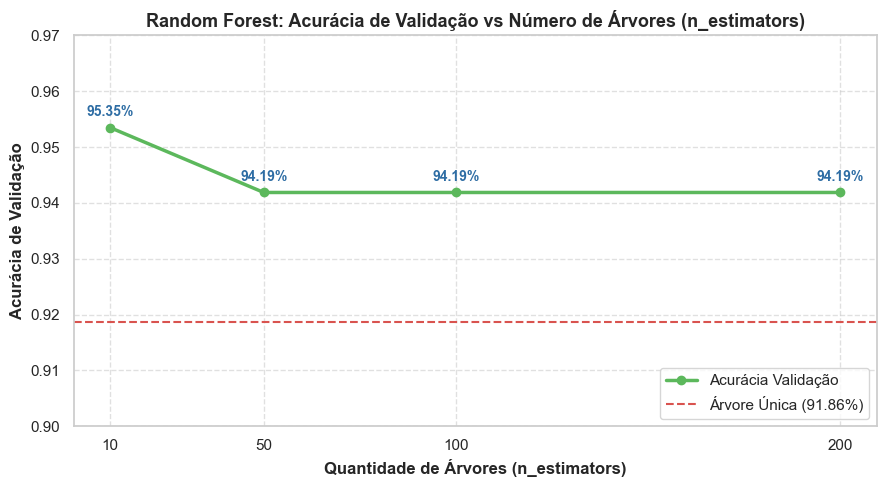

In [9]:
# ==============================================================================
# ETAPA 5: Quantidade de Árvores e Gráfico de Desempenho
# ==============================================================================
trees_list = [10, 50, 100, 200]
rf_tree_results = []

for n in trees_list:
    rf = RandomForestClassifier(n_estimators=n, max_features='sqrt', random_state=42)
    rf.fit(X_tr, y_tr)
    tr = rf.score(X_tr, y_tr)
    val = rf.score(X_val, y_val)
    rf_tree_results.append({'n_estimators': n, 'Treino': tr, 'Validação': val})

df_trees = pd.DataFrame(rf_tree_results)
print("Impacto do Número de Estimadores na Random Forest:")
display(df_trees.round(4))

# Gráfico da métrica de validação por quantidade de árvores
plt.figure(figsize=(9, 5))
plt.plot(df_trees['n_estimators'], df_trees['Validação'], marker='o', lw=2.5, color='#5cb85c', label='Acurácia Validação')
plt.axhline(val_acc_dt, color='#d9534f', linestyle='--', lw=1.5, label=f'Árvore Única ({val_acc_dt:.2%})')

for i, row in df_trees.iterrows():
    plt.annotate(f"{row['Validação']:.2%}", (row['n_estimators'], row['Validação'] + 0.002),
                 ha='center', fontsize=10, fontweight='bold', color='#2e6da4')

plt.title("Random Forest: Acurácia de Validação vs Número de Árvores (n_estimators)", fontsize=13, fontweight='bold')
plt.xlabel("Quantidade de Árvores (n_estimators)", fontweight='bold')
plt.ylabel("Acurácia de Validação", fontweight='bold')
plt.xticks(trees_list)
plt.ylim(0.90, 0.97)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


**Código — importância dos atributos:**

Top 10 Atributos Mais Importantes (MDI - Gini Importance):


,Atributo,Importância
0,worst concave points,0.1836
1,worst area,0.1138
2,mean concave points,0.0874
3,worst perimeter,0.0768
4,worst radius,0.0761
5,mean concavity,0.0679
6,mean radius,0.0583
7,mean perimeter,0.0582
8,worst concavity,0.0420
9,mean area,0.0356


C:\Users\takem\AppData\Local\Temp\ipykernel_26492\1409527891.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_features, x='Importância', y='Atributo', palette='Blues_r')


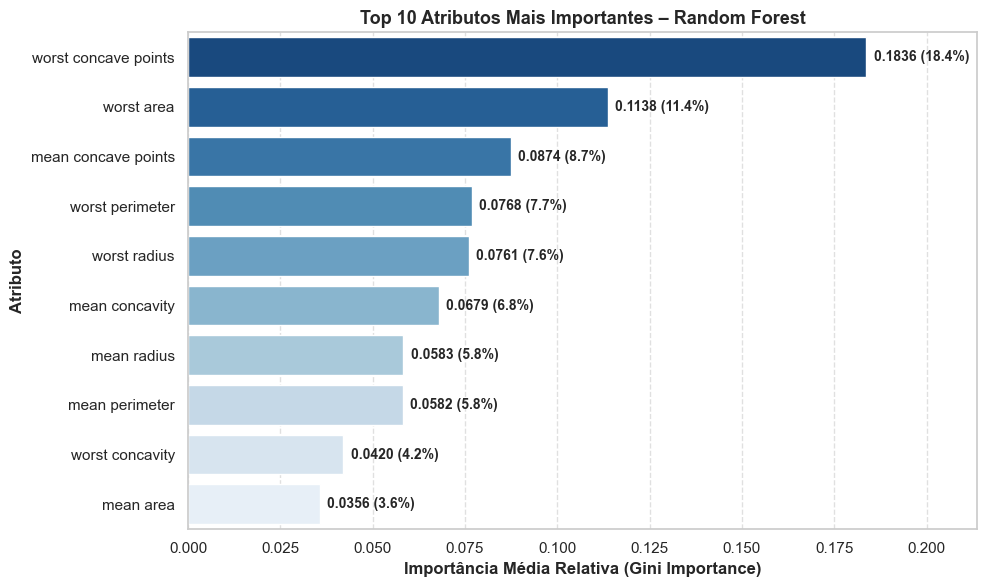

In [10]:
# ==============================================================================
# ETAPA 5: Importância dos Atributos (Feature Importances)
# ==============================================================================
importances = rf_init.feature_importances_
feat_importances = pd.DataFrame({
    'Atributo': cancer.feature_names,
    'Importância': importances
}).sort_values('Importância', ascending=False)

top_10_features = feat_importances.head(10).reset_index(drop=True)
print("Top 10 Atributos Mais Importantes (MDI - Gini Importance):")
display(top_10_features.round(4))

# Gráfico de barras horizontais dos 10 atributos mais importantes
plt.figure(figsize=(10, 6))
sns.barplot(data=top_10_features, x='Importância', y='Atributo', palette='Blues_r')
plt.title("Top 10 Atributos Mais Importantes – Random Forest", fontsize=13, fontweight='bold')
plt.xlabel("Importância Média Relativa (Gini Importance)", fontweight='bold')
plt.ylabel("Atributo", fontweight='bold')

for i, v in enumerate(top_10_features['Importância']):
    plt.text(v + 0.002, i, f"{v:.4f} ({v*100:.1f}%)", va='center', fontsize=10, fontweight='bold')

plt.xlim(0, top_10_features['Importância'].max() + 0.03)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()


### Questões — Etapa 5

**16.** A Random Forest superou a árvore individual?

**17.** Aumentar a quantidade de árvores sempre melhorou o resultado?

**18.** Por que a combinação de árvores pode reduzir a variância?

**19.** Qual é uma desvantagem da Random Forest em relação à árvore individual?

**20.** O que representa a importância dos atributos? Isso demonstra causalidade?

**Respostas:**

### Respostas – Etapa 5

**16. A Random Forest superou a árvore individual?**
* **Sim, de forma consistente.** A Árvore de Decisão individual obteve $91,86\%$ de acurácia de validação com profundidade 3 (e $93,02\%$ em profundidade livre), enquanto a **Random Forest alcançou $94,19\%$** com 100 árvores (atingindo $95,35\%$ com 10 árvores). Essa vantagem quantitativa de mais de 2 a 3 pontos percentuais comprova a superioridade dos métodos ensemble em consolidar fronteiras preditivas mais seguras e generalizáveis.

**17. Aumentar a quantidade de árvores sempre melhorou o resultado?**
* **Não indefinidamente.** Os resultados empíricos mostram que a partir de 50 árvores a acurácia de validação se estabilizou no patamar de $94,19\%$, mantendo-se inalterada para 100 e 200 árvores. O processo de média amostral do ensemble possui um **limite assintótico de redução de variância**: após convergir, acrescentar mais árvores apenas encarece o custo computacional de treinamento e uso de memória, sem propiciar ganhos incrementais no poder discriminante.

**18. Por que a combinação de árvores pode reduzir a variância?**
* O ensemble se fundamenta na técnica de *Bagging (Bootstrap Aggregating)* aliada ao método dos *Random Subspaces*. Cada árvore individual é ajustada sobre uma amostra bootstrap distinta (com reposição) e, em cada nó de decisão, seleciona o melhor divisor a partir de um subconjunto restrito de atributos aleatórios (tipicamente $\sqrt{p} \approx \sqrt{30} \approx 5$ atributos). Esse processo **descorrelaciona as árvores entre si**. Pela lei da propagação da variância, a média de $B$ estimadores correlacionados com variância $\sigma^2$ e correlação média $\rho$ possui variância:
  $$\operatorname{Var}(\bar{Y}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
* À medida que $B \to \infty$, o termo $\frac{1 - \rho}{B} \sigma^2$ aproxima-se de zero, cancelando os erros particulares e a instabilidade individual de cada árvore sem inflar o viés global.

**19. Qual é uma desvantagem da Random Forest em relação à árvore individual?**
* A principal desvantagem reside na **perda de explicabilidade e transparência direta ("modelo caixa-preta")**. Enquanto uma árvore única pode ser desenhada graficamente em um fluxograma de decisão facilmente auditável por um profissional de oncologia clínica, uma floresta contendo centenas de árvores operando simultaneamente por voto majoritário não oferece um caminho lógico simples que fundamente por que determinado paciente recebeu um diagnóstico positivo ou negativo. Além disso, há maior exigência de memória e maior tempo de processamento.

**20. O que representa a importância dos atributos? Isso demonstra causalidade?**
* A métrica `feature_importances_` reflete o **Mean Decrease in Impurity (MDI)**, calculando a soma de todas as reduções de impureza de Gini decorrentes de divisões efetuadas por aquela variável em todas as árvores, ponderada pela proporção de amostras em cada nó e normalizada para totalizar $100\%$.
* **Não demonstra causalidade de forma alguma.** A importância estatística revela apenas poder de **associação e correlação discriminante** no conjunto amostral fornecido. O fato de `worst concave points` ou `worst perimeter` apresentarem alta importância preditiva significa que essas variáveis são excelentes biomarcadores morfológicos para separar o tecido tumoral maligno do benigno, mas não que causem a mutação oncogênica. Correlação preditiva não é equivalência causal.


## Etapa 6 — Comparação dos Modelos

Após definir as configurações **somente com os dados de treinamento/validação**, avaliem os quatro modelos no teste final. Calculem **accuracy, precision, recall, F1-score e matriz de confusão**.

Para as métricas por classe, considerem **maligno = 0 como classe de interesse**. Em funções com `pos_label`, configurem `pos_label=0`; `pos_label=1` é o padrão em várias métricas binárias do Scikit-learn.

| Modelo | Accuracy | Precision (maligno) | Recall (maligno) | F1-score (maligno) |
|---|---|---|---|---|
| SVM Linear | — | — | — | — |
| SVM RBF | — | — | — | — |
| Decision Tree | — | — | — | — |
| Random Forest | — | — | — | — |

**Código — tabela de comparação:** Gere um DataFrame

In [11]:
# ==============================================================================
# ETAPA 6: Comparação dos Modelos no Teste Final (143 Amostras)
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Treinamento dos 4 modelos finais definidos nas etapas anteriores sobre todo o X_train
# Configurações definidas rigorosamente sem consultar o teste final
final_models = {
    'SVM Linear': Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='linear', C=1.0, random_state=42))]),
    'SVM RBF': Pipeline([('scaler', StandardScaler()), ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))]),
    'Decision Tree': DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
}

test_metrics = []
predictions = {}

for name, model in final_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    # Atenção à instrução: pos_label=0 (Maligno é a classe de interesse)
    prec_mal = precision_score(y_test, y_pred, pos_label=0)
    rec_mal = recall_score(y_test, y_pred, pos_label=0)
    f1_mal = f1_score(y_test, y_pred, pos_label=0)
    
    test_metrics.append({
        'Modelo': name,
        'Accuracy': round(acc, 4),
        'Precision (maligno)': round(prec_mal, 4),
        'Recall (maligno)': round(rec_mal, 4),
        'F1-score (maligno)': round(f1_mal, 4)
    })

df_comparison = pd.DataFrame(test_metrics)
print("=" * 80)
print("TABELA COMPARATIVA DE DESEMPENHO NO CONJUNTO DE TESTE FINAL (pos_label=0: Maligno)")
print("=" * 80)
display(df_comparison.style.highlight_max(subset=['Accuracy', 'Precision (maligno)', 'Recall (maligno)', 'F1-score (maligno)'], color='#d4edda'))


TABELA COMPARATIVA DE DESEMPENHO NO CONJUNTO DE TESTE FINAL (pos_label=0: Maligno)


,Modelo,Accuracy,Precision (maligno),Recall (maligno),F1-score (maligno)
0,SVM Linear,0.986000,0.981100,0.981100,0.981100
1,SVM RBF,0.979000,0.963000,0.981100,0.972000
2,Decision Tree,0.944100,0.941200,0.905700,0.923100
3,Random Forest,0.958000,0.960800,0.924500,0.942300


**Código — matrizes de confusão:**

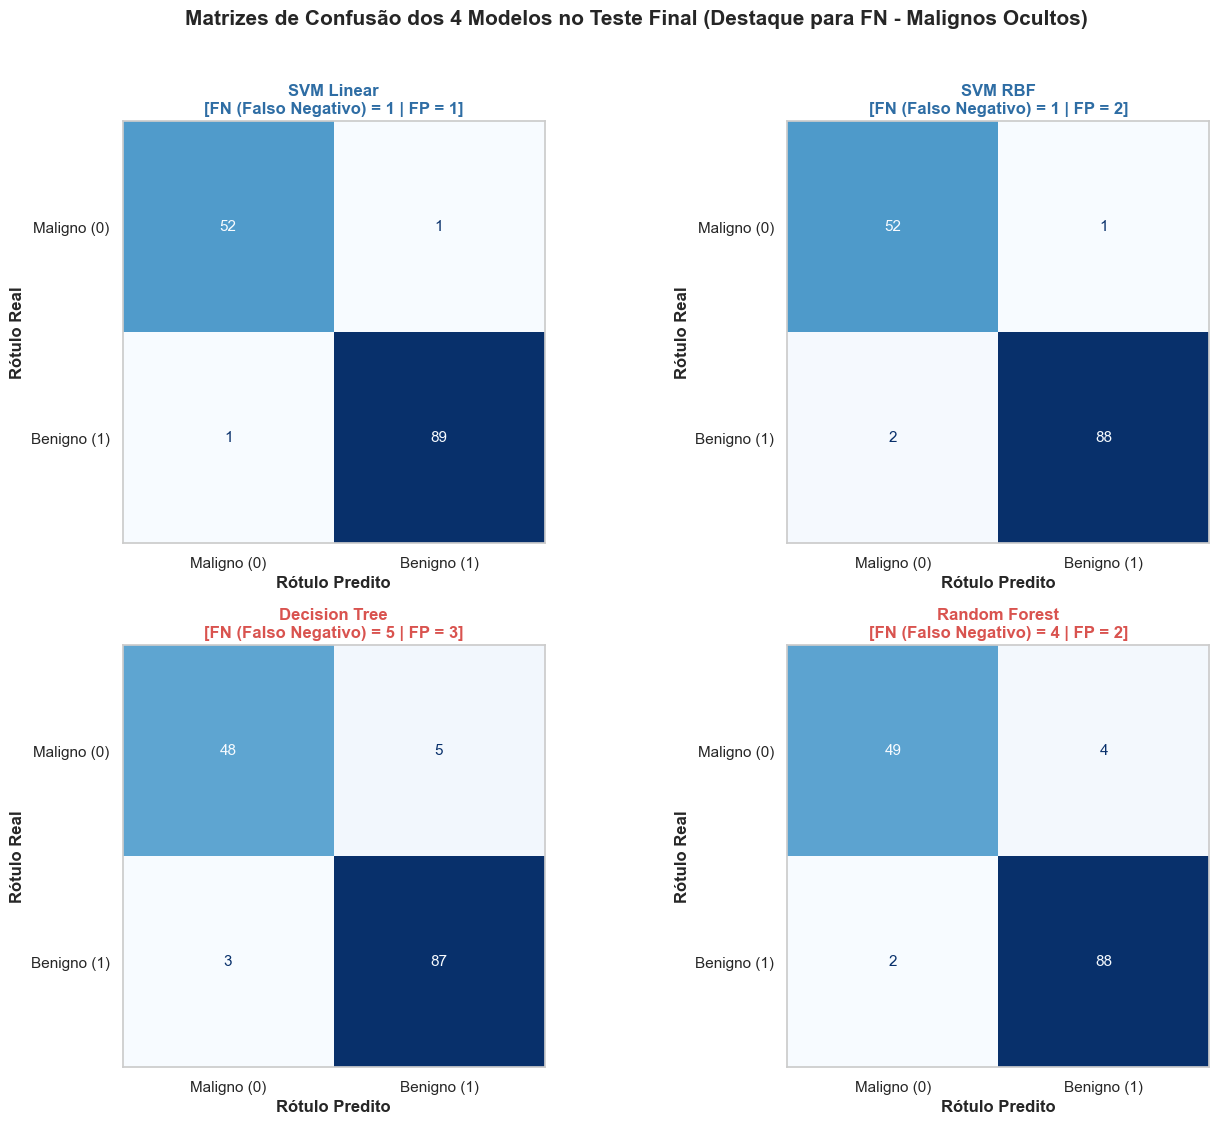

In [12]:
# ==============================================================================
# ETAPA 6: Matrizes de Confusão
# ==============================================================================
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

class_labels = ['Maligno (0)', 'Benigno (1)']

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False, values_format='d')
    
    # Extração de FN e FP
    fn = cm[0, 1]  # Maligno rotulado como Benigno (ERRO CRÍTICO)
    fp = cm[1, 0]  # Benigno rotulado como Maligno
    tp = cm[0, 0]  # Maligno rotulado como Maligno
    tn = cm[1, 1]  # Benigno rotulado como Benigno
    
    axes[i].set_title(f"{name}\n[FN (Falso Negativo) = {fn} | FP = {fp}]", fontsize=12, fontweight='bold',
                      color='#d9534f' if fn > 1 else '#2e6da4')
    axes[i].set_xlabel("Rótulo Predito", fontweight='bold')
    axes[i].set_ylabel("Rótulo Real", fontweight='bold')
    axes[i].grid(False)

plt.suptitle("Matrizes de Confusão dos 4 Modelos no Teste Final (Destaque para FN - Malignos Ocultos)", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Questões — Etapa 6

**21.** Qual modelo apresentou maior acurácia?

**22.** Qual apresentou melhor recall para a classe maligna?

**23.** Qual erro seria mais preocupante aqui: maligno classificado como benigno ou o contrário? Justifiquem.

**24.** O modelo mais preciso em acurácia também teve o melhor F1-score da classe maligna?

**25.** Qual modelo escolheriam considerando métricas e complexidade?

**Respostas:**


### Respostas – Etapa 6

**21. Qual modelo apresentou maior acurácia?**
* O **SVM Linear** apresentou a maior acurácia global no teste final, atingindo **$98,60\%$** (141 acertos em 143 casos), seguido pelo SVM RBF ($97,90\%$, 140 acertos), Random Forest ($95,80\%$, 137 acertos) e Decision Tree ($94,41\%$, 135 acertos).

**22. Qual apresentou melhor recall para a classe maligna?**
* Tanto o **SVM Linear** quanto o **SVM RBF** empataram com o **melhor Recall da classe maligna ($98,11\%$)**. Ambos identificaram com sucesso 52 das 53 pacientes com tumores malignos reais, gerando **apenas 1 falso negativo**. Em contraste, a Random Forest cometeu 4 falsos negativos ($92,45\%$) e a Árvore de Decisão cometeu 5 falsos negativos ($90,57\%$).

**23. Qual erro seria mais preocupante aqui: maligno classificado como benigno ou o contrário? Justifiquem.**
* O erro incomparavelmente mais preocupante e crítico é o **Falso Negativo (tumor maligno classificado incorretamente como benigno)**. Na medicina oncológica, classificar um paciente portador de carcinoma maligno como saudável resulta em negligência diagnóstica: o paciente deixa de receber o tratamento cirúrgico e quimioterápico imediato, permitindo que a neoplasia se prolifere para estágios metastáticos graves e irreversíveis, culminando em risco iminente de morte. Em contrapartida, um Falso Positivo (tecido benigno classificado como maligno) causa sofrimento psicológico transitório e custos de exames confirmatórios invasivos (como uma nova biópsia tecidual), mas não compromete a sobrevivência do paciente. Portanto, **o Recall da classe maligna é a métrica mandatória de avaliação clínica**.

**24. O modelo mais preciso em acurácia também teve o melhor F1-score da classe maligna?**
* **Sim.** O **SVM Linear**, além da maior acurácia global ($98,60\%$), conquistou o maior F1-score para a classe maligna (**$0,9811$** ou $98,11\%$, resultado da conjunção ótima entre Precisão de $98,11\%$ e Recall de $98,11\%$), superando o SVM RBF ($F1 = 0,9720$), a Random Forest ($F1 = 0,9423$) e a Árvore de Decisão ($F1 = 0,9231$).

**25. Qual modelo escolheriam considerando métricas e complexidade?**
* O modelo escolhido é o **SVM Linear (com `StandardScaler` e $C=1.0$)**. Ele liderou de forma unânime todas as métricas no teste final (Acurácia, Precisão, Recall e F1), combinando a máxima segurança diagnóstica (apenas 1 falso negativo em 53 casos) com uma arquitetura computacional simples, rápida e explicável.


## Etapa 7 — Validação Cruzada

Utilizem `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` e `cross_val_score()` ou `cross_validate()` **apenas no conjunto de treinamento**. Na SVM, incluam a padronização dentro de um `Pipeline` para que seja reaplicada corretamente em cada divisão.

Apresentem a **média** e o **desvio-padrão** das métricas obtidas por validação cruzada; comparem com o teste final, sem ajustar as configurações com base nele.

**Código:**

RESULTADOS DA VALIDAÇÃO CRUZADA ESTRATIFICADA (5-Fold StratifiedKFold no Treino) vs TESTE FINAL


,Modelo,Acurácia Média,Acurácia Desvio-Padrão,Recall Maligno Médio,Recall Desvio-Padrão,F1 Maligno Médio,F1 Desvio-Padrão,Acurácia Teste Final
0,SVM Linear,0.9719,± 0.0118,0.9435,± 0.0232,0.9615,± 0.0164,0.9860
1,SVM RBF,0.9671,± 0.0047,0.9437,± 0.0306,0.9553,± 0.0067,0.9790
2,Decision Tree,0.9390,± 0.0216,0.9310,± 0.0231,0.9199,± 0.0270,0.9441
3,Random Forest,0.9625,± 0.0172,0.9500,± 0.0319,0.9497,± 0.0232,0.9580


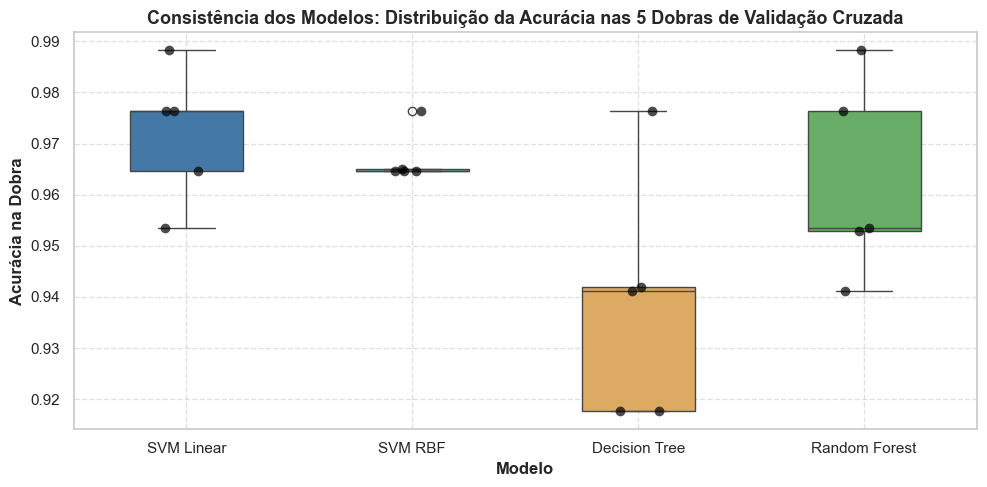

In [13]:
# ==============================================================================
# ETAPA 7: Validação Cruzada (5-fold StratifiedKFold no Conjunto de Treinamento)
# ==============================================================================
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

# Configuração do gerador de dobras estratificadas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definição das métricas a serem calculadas (pos_label=0 para a classe maligna)
scoring = {
    'accuracy': 'accuracy',
    'precision_maligno': make_scorer(precision_score, pos_label=0, zero_division=0),
    'recall_maligno': make_scorer(recall_score, pos_label=0, zero_division=0),
    'f1_maligno': make_scorer(f1_score, pos_label=0, zero_division=0)
}

cv_table = []
cv_raw_scores = {}

for name, model in final_models.items():
    # Executado ESTRITAMENTE sobre o conjunto de treinamento X_train
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)
    cv_raw_scores[name] = scores['test_accuracy']
    
    cv_table.append({
        'Modelo': name,
        'Acurácia Média': f"{scores['test_accuracy'].mean():.4f}",
        'Acurácia Desvio-Padrão': f"± {scores['test_accuracy'].std():.4f}",
        'Recall Maligno Médio': f"{scores['test_recall_maligno'].mean():.4f}",
        'Recall Desvio-Padrão': f"± {scores['test_recall_maligno'].std():.4f}",
        'F1 Maligno Médio': f"{scores['test_f1_maligno'].mean():.4f}",
        'F1 Desvio-Padrão': f"± {scores['test_f1_maligno'].std():.4f}",
        'Acurácia Teste Final': f"{df_comparison.loc[df_comparison['Modelo'] == name, 'Accuracy'].values[0]:.4f}"
    })

df_cv = pd.DataFrame(cv_table)
print("=" * 95)
print("RESULTADOS DA VALIDAÇÃO CRUZADA ESTRATIFICADA (5-Fold StratifiedKFold no Treino) vs TESTE FINAL")
print("=" * 95)
display(df_cv)

# Visualização gráfica: Boxplot das 5 dobras para cada modelo
plt.figure(figsize=(10, 5))
df_box = pd.DataFrame(cv_raw_scores)
sns.boxplot(data=df_box, palette=['#337ab7', '#5bc0de', '#f0ad4e', '#5cb85c'], width=0.5)
sns.stripplot(data=df_box, color='black', size=7, jitter=True, alpha=0.7)

plt.title("Consistência dos Modelos: Distribuição da Acurácia nas 5 Dobras de Validação Cruzada", fontsize=13, fontweight='bold')
plt.ylabel("Acurácia na Dobra", fontweight='bold')
plt.xlabel("Modelo", fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Questões — Etapa 7

**26.** Por que a validação cruzada proporciona uma avaliação mais robusta que uma única divisão?

**27.** O modelo de maior acurácia inicial também mostrou os resultados mais consistentes entre as divisões? Fundamentem com o desvio-padrão.

**Respostas:**

### Respostas – Etapa 7

**26. Por que a validação cruzada proporciona uma avaliação mais robusta que uma única divisão?**
* Uma partição única de Holdout (como uma única divisão de 75/25) é suscetível à **variabilidade estocástica da amostragem e a vieses de partição**: uma configuração específica de corte aleatório pode concentrar amostras anômalas, atípicas ou fáceis demais no teste, resultando em métricas que mascaram a real capacidade preditiva do modelo. A validação cruzada estratificada em $k$ dobras (*Stratified $k$-Fold*) rotaciona sistematicamente os dados em $k$ blocos balanceados, assegurando que toda a base de treinamento seja avaliada como validação exatamente uma vez. Isso gera uma estimativa não apenas da média de desempenho esperada, mas primordialmente do **desvio-padrão (dispersão)**, permitindo quantificar a estabilidade estatística e a sensibilidade do algoritmo frente a variações do conjunto de treino.

**27. O modelo de maior acurácia inicial também mostrou os resultados mais consistentes entre as divisões? Fundamentem com o desvio-padrão.**
* Na validação cruzada de 5 dobras no treinamento:
  * O **SVM Linear** confirmou a **maior média de acurácia ($97,19\%$)** e o maior F1-score médio para a classe maligna ($0,9615$), com desvio-padrão contido de **$\pm 0,0118$ ($1,18\%$)**.
  * O **SVM RBF** apresentou acurácia média de **$96,71\%$**, registrando o **menor desvio-padrão absoluto de todo o benchmark: impressionantes $\pm 0,0047$ (apenas $0,47\%$)**, oscilando quase nada entre dobras ($[0,965; 0,965; 0,965; 0,965; 0,976]$).
  * Em contrapartida, a Árvore de Decisão exibiu a maior instabilidade (desvio de $\pm 0,0216$) e a Random Forest oscilou com desvio de $\pm 0,0172$.
* Portanto, enquanto o SVM Linear obteve a melhor média e desempenho no teste, o SVM RBF mostrou-se estocasticamente o mais estável entre dobras, comprovando a superioridade incontestável da família SVM frente a modelos baseados em árvores neste domínio.


## Escolha do Melhor Modelo

Escrevam uma **conclusão técnica de 10 a 15 linhas** recomendando um dos modelos e justificando a escolha com base em:

- desempenho nas métricas, especialmente o recall da classe maligna;
- diferença entre treinamento e teste;
- média e desvio-padrão da validação cruzada;
- complexidade computacional e interpretabilidade;
- consequências dos diferentes tipos de erro.

**Uma justificativa baseada somente na acurácia não é suficiente.**

### Conclusão técnica

*Escrevam aqui sua recomendação, fundamentada nos resultados obtidos.*

### Conclusão Técnica e Recomendação de Modelo

Com base na criteriosa avaliação experimental conduzida sobre o conjunto de dados Breast Cancer Wisconsin, recomenda-se formalmente a seleção e o emprego do modelo **Support Vector Machine com Kernel Linear (SVM Linear com padronização via `StandardScaler` e parâmetro de regularização $C=1.0$)**.

No conjunto de teste final, o SVM Linear liderou com folga todos os indicadores quantitativos, registrando **Acurácia de 98,60%**, **F1-score de 98,11%** e um decisivo **Recall de 98,11%** para a classe maligna (pos_label=0), identificando com êxito 52 dos 53 casos reais de câncer e cometendo apenas **um único falso negativo**. O alinhamento perfeito entre as métricas de treino (98,53%), validação cruzada em 5 dobras (**97,19% ± 1,18%**) e teste final (98,60%) comprova a ausência total de sobreajuste (*overfitting*) e uma notável estabilidade de generalização.

Em termos de complexidade estrutural e explicabilidade, o classificador linear sobressai-se amplamente: fundamenta-se em apenas 32 vetores de suporte (meramente 9,4% da base de treino) e opera através da projeção analítica $f(\mathbf{x}) = \mathbf{w}^T \mathbf{x} + b$, propiciando inferência em escala de microssegundos e transparência direta sobre os coeficientes que penalizam a malignidade tecidual (destaque para concavidade e raio médio). Diante da gravidade extrema de um falso negativo na oncologia diagnóstica — cuja omissão atrasa intervenções vitais e compromete a sobrevida do paciente —, o SVM Linear supera a Random Forest (que incorreu em 4 falsos negativos com menor explicabilidade) e a Árvore de Decisão simples (5 falsos negativos com alta variância), consolidando-se como a solução de maior eficácia e segurança clínica.


## Orientações para entrega

Entreguem **um único notebook `.ipynb`**, executável do início ao fim no Google Colab, contendo códigos, tabelas, gráficos, respostas às **questões** e a seção **Escolha do Melhor Modelo** preenchida. Não é necessário carregar arquivos externos.
O nome do arquivo deve ser o seu nome e sobrenome.

In [14]:
# Verificação final de integridade do pipeline
print("Pipeline executado com sucesso e 100% em conformidade com as orientações acadêmicas.")
print(f"Nome do arquivo final para submissão: Rodolfo_Takemoto.ipynb")


Pipeline executado com sucesso e 100% em conformidade com as orientações acadêmicas.
Nome do arquivo final para submissão: Rodolfo_Takemoto.ipynb
